In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Import library

In [ ]:
# --------------------------
# 1) Import library
# --------------------------

import sys
import os
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# --------------------------
# Helper: cek dependensi
# --------------------------
required_pkgs = [
    # data handling & I/O
    "pandas", "numpy", "openpyxl",
    # visualization
    "matplotlib", "seaborn",
    # preprocessing & model selection
    "scikit-learn",
    # imbalance handling
    "imblearn",
    # tree boosters (opsional)
    "xgboost", "lightgbm",
    # interpretability (opsional)
    "shap",
    # persistence & util
    "joblib",
    # encoding helpers (opsional)
    "category_encoders",
    # missingness visualization (opsional)
    "missingno"
]

missing = []
for pkg in required_pkgs:
    try:
        __import__(pkg)
    except Exception:
        missing.append(pkg)

if missing:
    print("Paket berikut belum terpasang di environment:", missing)
    print("Silakan install, misalnya: pip install " + " ".join(missing))
else:
    print("Semua paket utama tersedia. Lanjutkan import...")

# --------------------------
# Imports (import sebenarnya; terpisah agar jelas)
# --------------------------
# Data handling
import pandas as pd
import numpy as np
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import numpy as np
import lightgbm as lgb
import joblib
import zipfile
import os
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    f1_score
)
import matplotlib.pyplot as plt


# I/O (excel support)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# (opsional, jika terpasang)
try:
    import missingno as msno
except Exception:
    msno = None

# Preprocessing & pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import category_encoders as ce

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# Optional boosters
try:
    from xgboost import XGBClassifier
except Exception:
    XGBClassifier = None

try:
    from lightgbm import LGBMClassifier
except Exception:
    LGBMClassifier = None

# Imbalanced data handling
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
except Exception:
    SMOTE = None
    ImbPipeline = None

# Evaluation / metrics
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, precision_recall_curve,
    accuracy_score, precision_score, recall_score, f1_score
)

# Interpretability (optional)
try:
    import shap
except Exception:
    shap = None

# Persistence / util
import joblib
import pickle

# Display settings (not mandatory)
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 100)
sns.set_style("whitegrid")

print("Imports completed. Ready to proceed.")


Paket berikut belum terpasang di environment: ['scikit-learn']
Silakan install, misalnya: pip install scikit-learn
Imports completed. Ready to proceed.


In [ ]:
pip install scikit-learn category_encoders


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 3.3 MB/s eta 0:00:00


In [ ]:
!pip install lightgbm --install-option=--gpu --install-option="--boost-root=/usr/local" --install-option="--no-cuda"


Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

no such option: --install-option


# 2. Load dataset

In [ ]:
from IPython.display import display

# --------------------------
# 2) Load Dataset & Data Dictionary
# --------------------------

# Load dataset utama (CSV)
data_path = "/content/loan_data_2007_2014.csv"
df = pd.read_csv(data_path, low_memory=False)

# --------------------------
# Informasi Dataset Utama
# --------------------------
print("===== INFORMASI DATASET UTAMA =====")
info_df = pd.DataFrame({
    "Metric": ["Jumlah Baris", "Jumlah Kolom"],
    "Value": [df.shape[0], df.shape[1]]
})
display(info_df)

print("\n===== CONTOH 5 DATA TERATAS =====")
display(df.head())

# --------------------------
# Struktur Kolom Dataset
# --------------------------
print("\n===== TIPE DATA KOLOM =====")
dtypes_table = pd.DataFrame({
    "Kolom": df.columns,
    "Tipe Data": df.dtypes.astype(str)
})
display(dtypes_table.head(85))

# --------------------------
# Missing Values
# --------------------------
print("\n===== MISSING VALUES =====")
missing_table = (
    df.isnull()
      .sum()
      .reset_index()
      .rename(columns={"index": "Kolom", 0: "Jumlah Missing"})
      .sort_values("Jumlah Missing", ascending=False)
)
display(missing_table.head(85))


===== INFORMASI DATASET UTAMA =====


,Metric,Value
0,Jumlah Baris,466285
1,Jumlah Kolom,75



===== CONTOH 5 DATA TERATAS =====


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,B2,NaN,10+ years,RENT,24000.0,Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0.0,Jan-85,1.0,NaN,NaN,3.0,0.0,13648,83.7,9.0,f,0.0,0.0,5861.071414,5831.78,5000.00,861.07,0.00,0.00,0.00,Jan-15,171.62,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,C4,Ryder,< 1 year,RENT,30000.0,Source Verified,Dec-11,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0.0,Apr-99,5.0,NaN,NaN,3.0,0.0,1687,9.4,4.0,f,0.0,0.0,1008.710000,1008.71,456.46,435.17,0.00,117.08,1.11,Apr-13,119.66,NaN,Sep-13,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252.0,Not Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,small_business,real estate business,606xx,IL,8.72,0.0,Nov-01,2.0,NaN,NaN,2.0,0.0,2956,98.5,10.0,f,0.0,0.0,3003.653644,3003.65,2400.00,603.65,0.00,0.00,0.00,Jun-14,649.91,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200.0,Source Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > to pay for prop...,other,personel,917xx,CA,20.00,0.0,Feb-96,1.0,35.0,NaN,10.0,0.0,5598,21.0,37.0,f,0.0,0.0,12226.302210,12226.30,10000.00,2209.33,16.97,0.00,0.00,Jan-15,357.48,NaN,Jan-15,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,B5,University Medical Group,1 year,RENT,80000.0,Source Verified,Dec-11,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > I plan on combi...,other,Personal,972xx,OR,17.94,0.0,Jan-96,0.0,38.0,NaN,15.0,0.0,27783,53.9,38.0,f,766.9,766.9,3242.170000,3242.17,2233.10,1009.07,0.00,0.00,0.00,Jan-16,67.79,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



===== TIPE DATA KOLOM =====


,Kolom,Tipe Data
Unnamed: 0,Unnamed: 0,int64
id,id,int64
member_id,member_id,int64
loan_amnt,loan_amnt,int64
funded_amnt,funded_amnt,int64
funded_amnt_inv,funded_amnt_inv,float64
term,term,object
int_rate,int_rate,float64
installment,installment,float64
grade,grade,object



===== MISSING VALUES =====


,Kolom,Jumlah Missing
69,max_bal_bc,466285
68,open_rv_24m,466285
72,inq_fi,466285
67,open_rv_12m,466285
66,il_util,466285
64,mths_since_rcnt_il,466285
65,total_bal_il,466285
63,open_il_24m,466285
62,open_il_12m,466285
61,open_il_6m,466285


# EDA

===== DATASET INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   id                           466285 non-null  int64  
 2   member_id                    466285 non-null  int64  
 3   loan_amnt                    466285 non-null  int64  
 4   funded_amnt                  466285 non-null  int64  
 5   funded_amnt_inv              466285 non-null  float64
 6   term                         466285 non-null  object 
 7   int_rate                     466285 non-null  float64
 8   installment                  466285 non-null  float64
 9   grade                        466285 non-null  object 
 10  sub_grade                    466285 non-null  object 
 11  emp_title                    438697 non-null  object 
 12  emp_length                   4452

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,466285.0,2.331420e+05,1.346050e+05,0.00,1.165710e+05,2.331420e+05,3.497130e+05,4.662840e+05
id,466285.0,1.307973e+07,1.089371e+07,54734.00,3.639987e+06,1.010790e+07,2.073121e+07,3.809811e+07
member_id,466285.0,1.459766e+07,1.168237e+07,70473.00,4.379705e+06,1.194108e+07,2.300154e+07,4.086083e+07
loan_amnt,466285.0,1.431728e+04,8.286509e+03,500.00,8.000000e+03,1.200000e+04,2.000000e+04,3.500000e+04
funded_amnt,466285.0,1.429180e+04,8.274371e+03,500.00,8.000000e+03,1.200000e+04,2.000000e+04,3.500000e+04
funded_amnt_inv,466285.0,1.422233e+04,8.297638e+03,0.00,8.000000e+03,1.200000e+04,1.995000e+04,3.500000e+04
int_rate,466285.0,1.382924e+01,4.357587e+00,5.42,1.099000e+01,1.366000e+01,1.649000e+01,2.606000e+01
installment,466285.0,4.320612e+02,2.434855e+02,15.67,2.566900e+02,3.798900e+02,5.665800e+02,1.409990e+03
annual_inc,466281.0,7.327738e+04,5.496357e+04,1896.00,4.500000e+04,6.300000e+04,8.896000e+04,7.500000e+06
dti,466285.0,1.721876e+01,7.851121e+00,0.00,1.136000e+01,1.687000e+01,2.278000e+01,3.999000e+01



===== RAW LOAN STATUS DISTRIBUTION =====
loan_status
Current                                                224226
Fully Paid                                             184739
Charged Off                                             42475
Late (31-120 days)                                       6900
In Grace Period                                          3146
Does not meet the credit policy. Status:Fully Paid       1988
Late (16-30 days)                                        1218
Default                                                   832
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

===== BINARY CREDIT RISK DISTRIBUTION =====
credit_risk
0    414860
1     51425
Name: count, dtype: int64


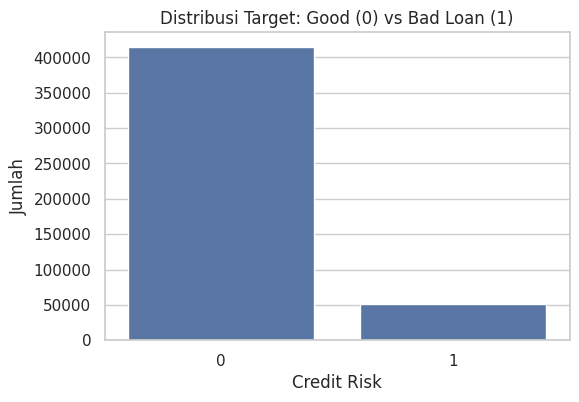


Numerical Features: 54
Categorical Features: 22


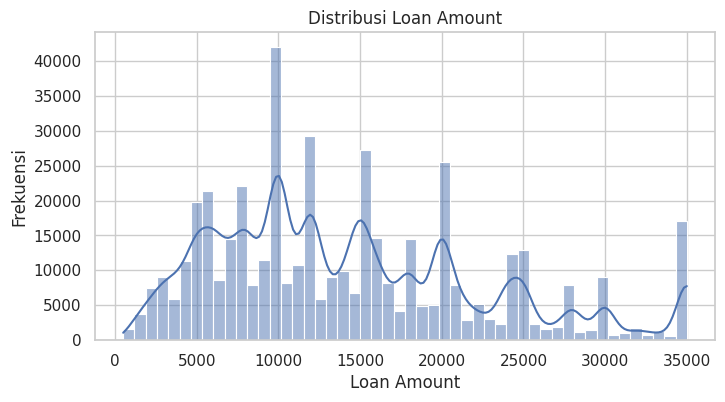

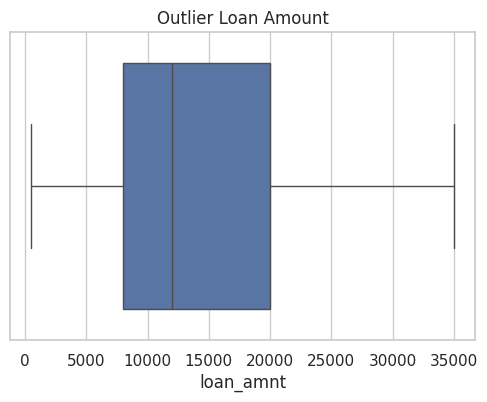

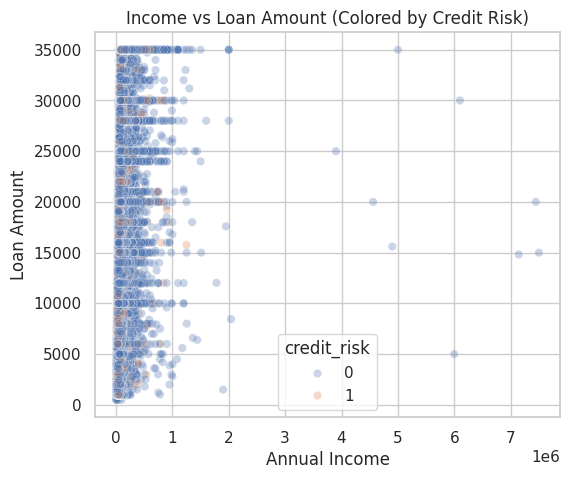

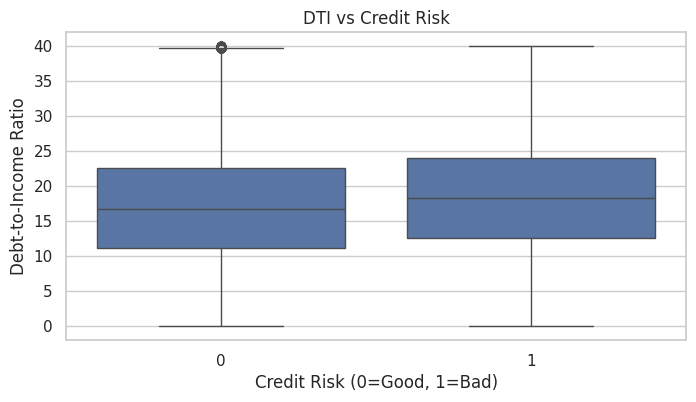

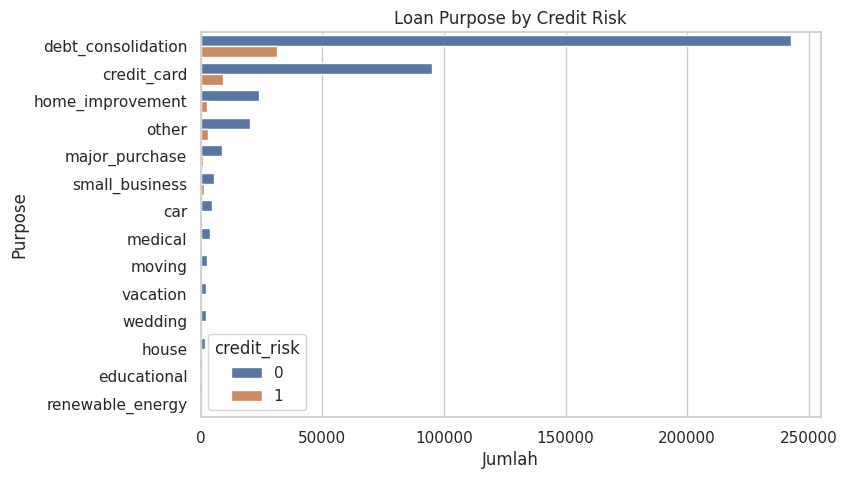

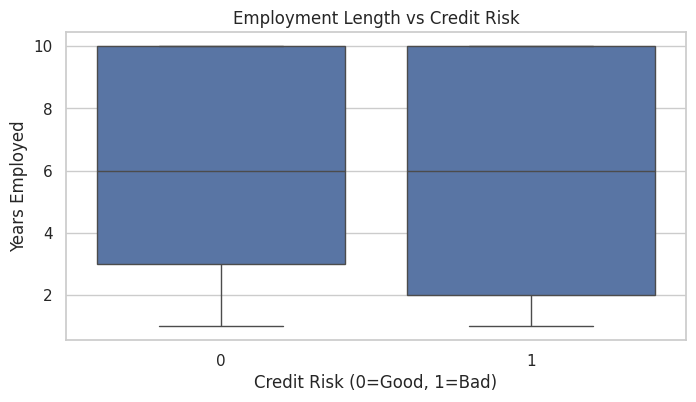

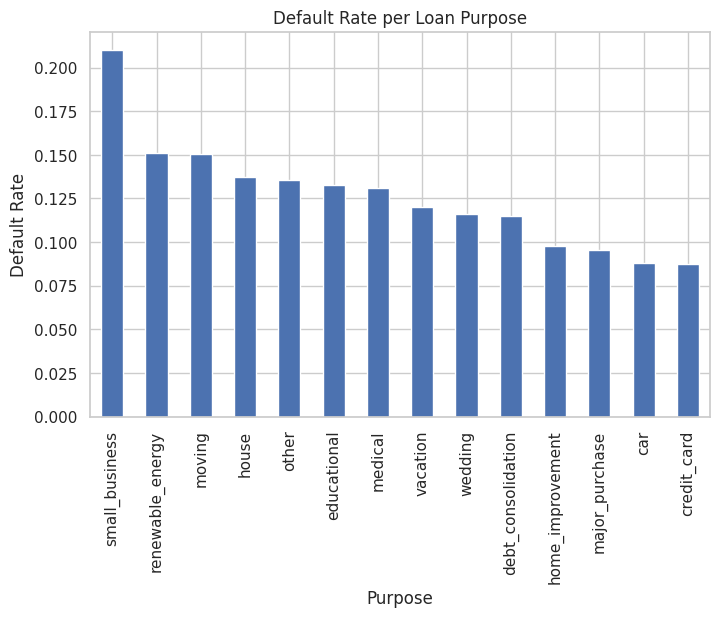


===== DEFAULT RATE BY PURPOSE =====


,credit_risk
purpose,
small_business,0.210181
renewable_energy,0.150997
moving,0.150301
house,0.137065
other,0.135838
educational,0.132701
medical,0.130813
vacation,0.120225
wedding,0.116090


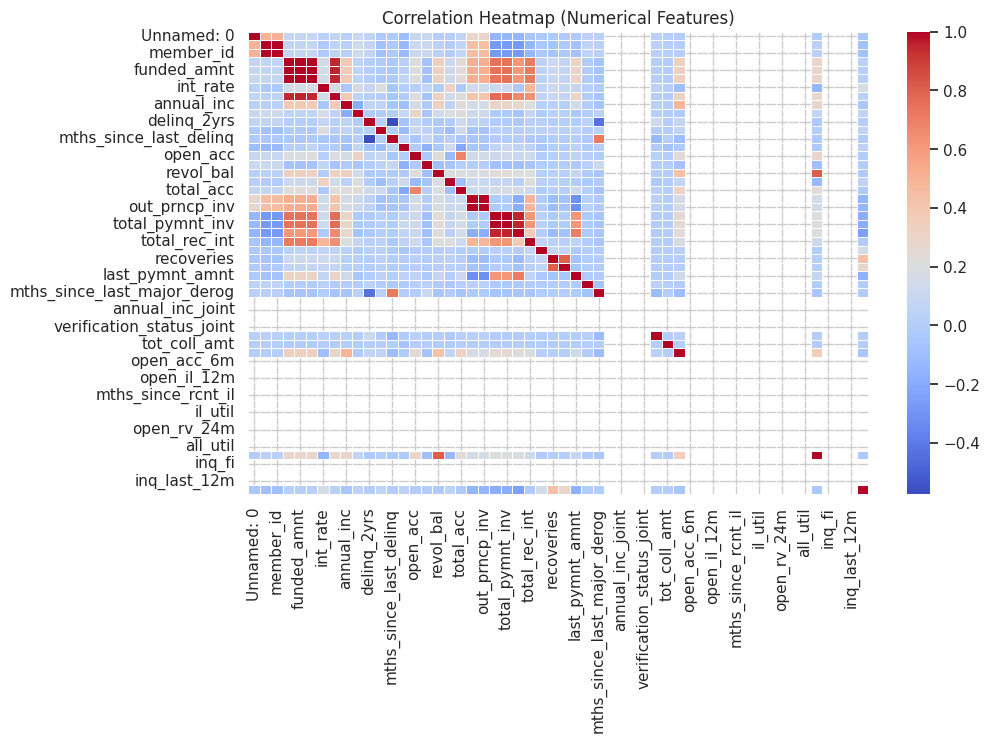


===== MISSING VALUE RATIO (TOP 15) =====


,0
annual_inc_joint,1.0
total_cu_tl,1.0
inq_fi,1.0
all_util,1.0
max_bal_bc,1.0
open_rv_24m,1.0
open_rv_12m,1.0
il_util,1.0
total_bal_il,1.0
mths_since_rcnt_il,1.0


In [ ]:
# ==========================================
# CREDIT RISK EDA - ID/X PARTNERS STYLE
# Dataset: loan_data_2007_2014.csv
# Target: Binary Default Risk (Good vs Bad Loan)
# ==========================================

sns.set(style="whitegrid")

# --------------------------
# Load Data
# --------------------------
df = pd.read_csv("/content/loan_data_2007_2014.csv", low_memory=False)

# --------------------------
# 1. DATA OVERVIEW
# --------------------------
print("===== DATASET INFO =====")
df.info()

print("\n===== DESCRIPTIVE STATISTICS (NUMERIC) =====")
display(df.describe().T)

# --------------------------
# 2. TARGET DEFINITION (BUSINESS LOGIC)
# --------------------------
print("\n===== RAW LOAN STATUS DISTRIBUTION =====")
print(df['loan_status'].value_counts())

# Define binary risk label
bad_status = [
    "Charged Off",
    "Default",
    "Late (31-120 days)",
    "Late (16-30 days)"
]

df['credit_risk'] = df['loan_status'].apply(
    lambda x: 1 if x in bad_status else 0
)

print("\n===== BINARY CREDIT RISK DISTRIBUTION =====")
print(df['credit_risk'].value_counts())

plt.figure(figsize=(6,4))
sns.countplot(x='credit_risk', data=df)
plt.title("Distribusi Target: Good (0) vs Bad Loan (1)")
plt.xlabel("Credit Risk")
plt.ylabel("Jumlah")
plt.show()

# --------------------------
# 3. FEATURE TYPE IDENTIFICATION
# --------------------------
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

print("\nNumerical Features:", len(numeric_cols))
print("Categorical Features:", len(categorical_cols))

# --------------------------
# 4. DISTRIBUSI JUMLAH PINJAMAN
# --------------------------
plt.figure(figsize=(8,4))
sns.histplot(df['loan_amnt'], bins=50, kde=True)
plt.title("Distribusi Loan Amount")
plt.xlabel("Loan Amount")
plt.ylabel("Frekuensi")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x=df['loan_amnt'])
plt.title("Outlier Loan Amount")
plt.show()

# --------------------------
# 5. HUBUNGAN PENDAPATAN VS JUMLAH PINJAMAN
# --------------------------
plt.figure(figsize=(6,5))
sns.scatterplot(
    x='annual_inc',
    y='loan_amnt',
    hue='credit_risk',
    data=df,
    alpha=0.3
)
plt.title("Income vs Loan Amount (Colored by Credit Risk)")
plt.xlabel("Annual Income")
plt.ylabel("Loan Amount")
plt.show()

# --------------------------
# 6. DTI BERDASARKAN STATUS PINJAMAN
# --------------------------
plt.figure(figsize=(8,4))
sns.boxplot(x='credit_risk', y='dti', data=df)
plt.title("DTI vs Credit Risk")
plt.xlabel("Credit Risk (0=Good, 1=Bad)")
plt.ylabel("Debt-to-Income Ratio")
plt.show()

# --------------------------
# 7. TUJUAN PINJAMAN
# --------------------------
plt.figure(figsize=(8,5))
sns.countplot(
    y='purpose',
    hue='credit_risk',
    data=df,
    order=df['purpose'].value_counts().index
)
plt.title("Loan Purpose by Credit Risk")
plt.xlabel("Jumlah")
plt.ylabel("Purpose")
plt.show()

# --------------------------
# 8. LAMA BEKERJA vs RISIKO
# --------------------------
df['emp_length_clean'] = (
    df['emp_length']
    .str.extract('(\d+)')
    .astype(float)
)

plt.figure(figsize=(8,4))
sns.boxplot(x='credit_risk', y='emp_length_clean', data=df)
plt.title("Employment Length vs Credit Risk")
plt.xlabel("Credit Risk (0=Good, 1=Bad)")
plt.ylabel("Years Employed")
plt.show()

# --------------------------
# 9. DEFAULT RATE ANALYSIS (BUSINESS INSIGHT)
# --------------------------
default_by_purpose = (
    df.groupby('purpose')['credit_risk']
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))
default_by_purpose.plot(kind='bar')
plt.title("Default Rate per Loan Purpose")
plt.ylabel("Default Rate")
plt.xlabel("Purpose")
plt.show()

print("\n===== DEFAULT RATE BY PURPOSE =====")
display(default_by_purpose)

# --------------------------
# 10. CORRELATION HEATMAP (NUMERIC)
# --------------------------
plt.figure(figsize=(10,6))
sns.heatmap(
    df[numeric_cols].corr(),
    cmap='coolwarm',
    linewidths=0.5
)
plt.title("Correlation Heatmap (Numerical Features)")
plt.show()

# --------------------------
# 11. DATA QUALITY CHECK
# --------------------------
missing_ratio = (
    df.isnull().mean()
      .sort_values(ascending=False)
)

print("\n===== MISSING VALUE RATIO (TOP 15) =====")
display(missing_ratio.head(15))


## Data Quality & Feature Diagnostics

### FULL UNIQUE VALUE CHECK & FEATURE VARIATION CHECK (LOW VARIANCE)

In [ ]:
print("\n===== UNIQUE VALUE COUNT (TOP 20 FEATURES) =====")

unique_counts = (
    df.nunique()
      .sort_values(ascending=False)
)

display(unique_counts.head(20))

print("\n===== LOW CARDINALITY FEATURES (<=5 UNIQUE) =====")
display(unique_counts[unique_counts <= 5])

num_variance = df[numeric_cols].var().sort_values()
display(num_variance.head(10))




===== UNIQUE VALUE COUNT (TOP 20 FEATURES) =====


,0
Unnamed: 0,466285
id,466285
member_id,466285
url,466285
total_pymnt,351609
total_pymnt_inv,347659
total_rec_int,270249
tot_cur_bal,220690
emp_title,205475
last_pymnt_amnt,198194



===== LOW CARDINALITY FEATURES (<=5 UNIQUE) =====


,0
verification_status,3
term,2
initial_list_status,2
pymnt_plan,2
credit_risk,2
policy_code,1
application_type,1
verification_status_joint,0
open_acc_6m,0
annual_inc_joint,0


,0
policy_code,0.000000
acc_now_delinq,0.004711
collections_12_mths_ex_med,0.011804
credit_risk,0.098124
pub_rec,0.260981
delinq_2yrs,0.635791
inq_last_6mths,1.191586
int_rate,18.988561
open_acc,24.875417
total_rec_late_fee,27.727909


### DUPLICATE CHECK & MISSING VALUE SUMMARY

===== DUPLICATED RECORD CHECK =====
Total duplicated rows: 0

===== MISSING VALUE SUMMARY (TOP 20) =====


,Kolom,Jumlah Missing
54,annual_inc_joint,466285
73,total_cu_tl,466285
72,inq_fi,466285
70,all_util,466285
69,max_bal_bc,466285
68,open_rv_24m,466285
67,open_rv_12m,466285
66,il_util,466285
65,total_bal_il,466285
64,mths_since_rcnt_il,466285


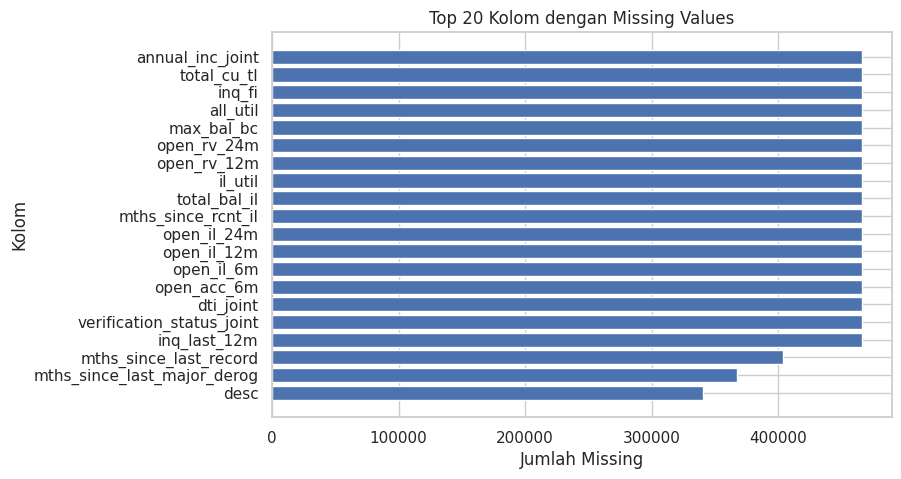

In [ ]:
from IPython.display import display
import matplotlib.pyplot as plt

# --------------------------
# DUPLICATE CHECK
# --------------------------
print("===== DUPLICATED RECORD CHECK =====")
dup_count = df.duplicated().sum()
print(f"Total duplicated rows: {dup_count}")

# --------------------------
# MISSING VALUE SUMMARY
# --------------------------
print("\n===== MISSING VALUE SUMMARY (TOP 20) =====")

missing_summary = (
    df.isnull()
      .sum()
      .reset_index()
      .rename(columns={"index": "Kolom", 0: "Jumlah Missing"})
      .sort_values("Jumlah Missing", ascending=False)
)

display(missing_summary.head(20))

# --------------------------
# VISUALISASI MISSING (OPSIONAL)
# --------------------------
plt.figure(figsize=(8, 5))
plt.barh(
    missing_summary.head(20)["Kolom"],
    missing_summary.head(20)["Jumlah Missing"]
)
plt.xlabel("Jumlah Missing")
plt.ylabel("Kolom")
plt.title("Top 20 Kolom dengan Missing Values")
plt.gca().invert_yaxis()
plt.show()


### OUTLIER & SKEWNESS ANALYSIS


===== SKEWNESS (TOP 10 MOST SKEWED FEATURES) =====


,0
tot_coll_amt,618.273011
total_rev_hi_lim,100.585590
collections_12_mths_ex_med,31.220302
annual_inc,29.568905
collection_recovery_fee,22.236096
acc_now_delinq,20.798291
revol_bal,19.476291
pub_rec,14.941355
total_rec_late_fee,13.843497
recoveries,13.149942



===== OUTLIER RATIO (TOP 10) =====


,outlier_ratio
delinq_2yrs,0.178650
last_pymnt_amnt,0.150865
pub_rec,0.131600
credit_risk,0.110287
tot_coll_amt,0.106694
inq_last_6mths,0.078890
total_rec_int,0.066779
recoveries,0.052266
out_prncp_inv,0.050143
out_prncp,0.050036


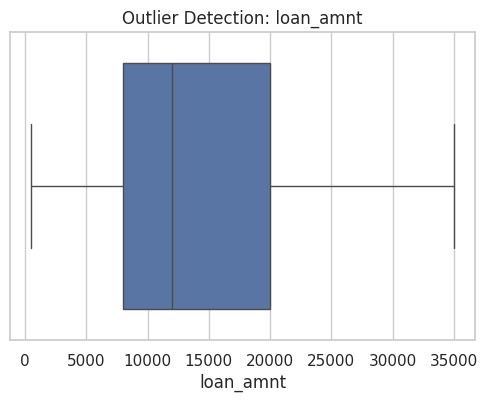

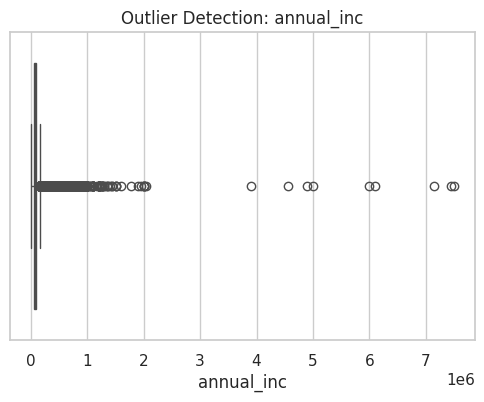

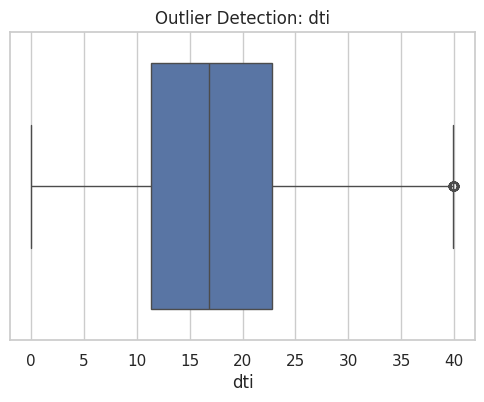

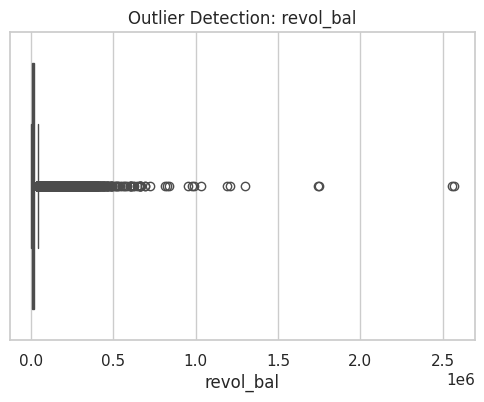

In [ ]:
print("\n===== SKEWNESS (TOP 10 MOST SKEWED FEATURES) =====")
skewed_features = df[numeric_cols].skew().sort_values(ascending=False)
display(skewed_features.head(10))

def outlier_ratio(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return ((series < lower) | (series > upper)).mean()

outlier_summary = pd.DataFrame({
    "outlier_ratio": df[numeric_cols].apply(outlier_ratio)
}).sort_values(by="outlier_ratio", ascending=False)

print("\n===== OUTLIER RATIO (TOP 10) =====")
display(outlier_summary.head(10))

important_num_features = ['loan_amnt', 'annual_inc', 'dti', 'revol_bal']

for col in important_num_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Detection: {col}")
    plt.show()



# Feature Engineering & Data Preparation for Modeling

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import os
import joblib

# --------------------------
# 0. COPY DATA
# --------------------------
data = df.copy()

# --------------------------
# 1. DROP FEATURE GROUPS
# --------------------------
# Fitur yang memang harus di-drop karena:
# - ID / tracking
# - Hanya meta (url, desc, title, emp_title)
# - Full missing
id_features = [
    "Unnamed: 0", "id", "member_id",
    "url", "desc", "title", "emp_title", "zip_code"
]

full_missing_features = [
    "annual_inc_joint", "dti_joint", "verification_status_joint",
    "open_acc_6m", "open_il_6m", "open_il_12m", "open_il_24m",
    "mths_since_rcnt_il", "total_bal_il", "il_util",
    "open_rv_12m", "open_rv_24m", "max_bal_bc", "all_util",
    "inq_fi", "total_cu_tl", "inq_last_12m"
]

low_variance_features = [
    "policy_code", "application_type", "pymnt_plan"
]

drop_features = id_features + full_missing_features + low_variance_features
data.drop(columns=[c for c in drop_features if c in data.columns], inplace=True)

# --------------------------
# 2. LABEL MAPPING (BUSINESS LOGIC)
# --------------------------
good_loans = [
    "Fully Paid",
    "Current",
    "In Grace Period",
    "Does not meet the credit policy. Status:Fully Paid"
]

bad_loans = [
    "Charged Off",
    "Default",
    "Late (16-30 days)",
    "Late (31-120 days)",
    "Does not meet the credit policy. Status:Charged Off"
]

data["credit_risk"] = data["loan_status"].apply(lambda x: 0 if x in good_loans else 1)
print("===== CREDIT RISK DISTRIBUTION =====")
print(data["credit_risk"].value_counts(normalize=True))

# --------------------------
# 3. TARGET SEPARATION
# --------------------------
y = data["credit_risk"]
X = data.drop(columns=["credit_risk", "loan_status"])

# --------------------------
# 4. FEATURE TYPE DETECTION
# --------------------------
num_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_features = X.select_dtypes(include=["object"]).columns.tolist()

# --------------------------
# 5. TRAIN / VAL / TEST SPLIT
# --------------------------
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42
)

# --------------------------
# 6. MISSING VALUE IMPUTATION
# --------------------------
# Numerical → median
num_medians = {}
for col in num_features:
    median_val = X_train[col].median()
    num_medians[col] = median_val
    X_train[col] = X_train[col].fillna(median_val)
    X_val[col] = X_val[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

# Categorical → "Unknown"
for col in cat_features:
    X_train[col] = X_train[col].fillna("Unknown")
    X_val[col] = X_val[col].fillna("Unknown")
    X_test[col] = X_test[col].fillna("Unknown")

# Behavioral / historical delay → -1 = never occurred
behavior_cols = [
    "mths_since_last_delinq",
    "mths_since_last_record",
    "mths_since_last_major_derog"
]

for col in behavior_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].fillna(-1)
        X_val[col] = X_val[col].fillna(-1)
        X_test[col] = X_test[col].fillna(-1)

# --------------------------
# 7. LOG TRANSFORMATION (NUMERIC SKEWED)
# --------------------------
skewed_cols = [
    "annual_inc", "revol_bal", "tot_coll_amt", "total_rev_hi_lim"
]

for col in skewed_cols:
    if col in X_train.columns:
        X_train[col] = np.log1p(X_train[col])
        X_val[col] = np.log1p(X_val[col])
        X_test[col] = np.log1p(X_test[col])

# --------------------------
# 8. CATEGORY TYPE
# --------------------------
for col in cat_features:
    X_train[col] = X_train[col].astype("category")
    X_val[col] = X_val[col].astype("category")
    X_test[col] = X_test[col].astype("category")

# --------------------------
# 9. SCALE POS WEIGHT (CLASS IMBALANCE)
# --------------------------
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# --------------------------
# 10. FEATURE INSPECTION (MASA DEPAN / RETROSPECTIVE)
# --------------------------
# Fitur yang mengandung info masa depan tapi relevan untuk retrospective analysis
future_features = [
    "out_prncp", "out_prncp_inv",
    "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int",
    "total_rec_late_fee", "recoveries",
    "collection_recovery_fee",
    "last_pymnt_amnt"
]

print("\n===== FUTURE FEATURES (USED IN RETROSPECTIVE MODELING) =====")
for f in future_features:
    if f in df.columns:
        print(f, "- kept for modeling")

# --------------------------
# 11. SUMMARY
# --------------------------
print("\n===== PREPROCESSING COMPLETE (LIGHTGBM NATIVE READY) =====")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Scale Pos Weight:", round(scale_pos_weight, 2))
print("Categorical Features:", len(cat_features))
print("Numerical Features:", len(num_features))


===== CREDIT RISK DISTRIBUTION =====
credit_risk
0    0.888081
1    0.111919
Name: proportion, dtype: float64

===== FUTURE FEATURES (USED IN RETROSPECTIVE MODELING) =====
out_prncp - kept for modeling
out_prncp_inv - kept for modeling
total_pymnt - kept for modeling
total_pymnt_inv - kept for modeling
total_rec_prncp - kept for modeling
total_rec_int - kept for modeling
total_rec_late_fee - kept for modeling
recoveries - kept for modeling
collection_recovery_fee - kept for modeling
last_pymnt_amnt - kept for modeling

===== PREPROCESSING COMPLETE (LIGHTGBM NATIVE READY) =====
Train: (279771, 46)
Validation: (93257, 46)
Test: (93257, 46)
Scale Pos Weight: 7.93
Categorical Features: 14
Numerical Features: 32


## SAVE ARTIFACTS

In [ ]:
import os
import shutil
import joblib
import pandas as pd
import zipfile

# --------------------------
# 0. CREATE ARTIFACTS FOLDER
# --------------------------
artifacts_dir = "artifacts"
os.makedirs(artifacts_dir, exist_ok=True)

# --------------------------
# 1. SAVE FEATURES & TARGETS
# --------------------------
# Features
X_train.to_parquet(os.path.join(artifacts_dir, "X_train.parquet"))
X_val.to_parquet(os.path.join(artifacts_dir, "X_val.parquet"))
X_test.to_parquet(os.path.join(artifacts_dir, "X_test.parquet"))

# Targets
y_train.to_frame("credit_risk").to_parquet(os.path.join(artifacts_dir, "y_train.parquet"))
y_val.to_frame("credit_risk").to_parquet(os.path.join(artifacts_dir, "y_val.parquet"))
y_test.to_frame("credit_risk").to_parquet(os.path.join(artifacts_dir, "y_test.parquet"))

# --------------------------
# 2. SAVE METADATA
# --------------------------
metadata = {
    "num_features": num_features,
    "cat_features": cat_features,
    "scale_pos_weight": scale_pos_weight,
    "train_size": X_train.shape[0],
    "val_size": X_val.shape[0],
    "test_size": X_test.shape[0],
    "num_medians": num_medians
}

joblib.dump(metadata, os.path.join(artifacts_dir, "metadata.pkl"))

print("===== ARTIFACTS SAVED SUCCESSFULLY =====")





===== ARTIFACTS SAVED SUCCESSFULLY =====


## ZIP ARTIFACTS

In [ ]:
# --------------------------
# 3. ZIP ARTIFACTS
# --------------------------
zip_path = "credit_risk_artifacts.zip"

# Remove existing zip if exists
if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive(
    base_name="credit_risk_artifacts",
    format="zip",
    root_dir=artifacts_dir
)

print("===== ARTIFACTS ZIPPED SUCCESSFULLY =====")
print("File:", zip_path)

===== ARTIFACTS ZIPPED SUCCESSFULLY =====
File: credit_risk_artifacts.zip


## LOAD ARTIFACTS

In [ ]:
import os
import zipfile
import pandas as pd
import joblib

# --------------------------
# 4. UNZIP & LOAD ARTIFACTS
# --------------------------

zip_path = "credit_risk_artifacts.zip"    # <-- harus didefinisikan sebagai string
extract_path = "artifacts"                # folder tujuan ekstraksi

# Extract only if folder empty or missing parquet files
if not all(os.path.exists(os.path.join(extract_path, f)) for f in [
    "X_train.parquet", "X_val.parquet", "X_test.parquet",
    "y_train.parquet", "y_val.parquet", "y_test.parquet",
    "metadata.pkl"
]):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

print("===== ARTIFACTS EXTRACTED =====")

# Load datasets
X_train = pd.read_parquet(os.path.join(extract_path, "X_train.parquet"))
X_val   = pd.read_parquet(os.path.join(extract_path, "X_val.parquet"))
X_test  = pd.read_parquet(os.path.join(extract_path, "X_test.parquet"))

y_train = pd.read_parquet(os.path.join(extract_path, "y_train.parquet")).squeeze()
y_val   = pd.read_parquet(os.path.join(extract_path, "y_val.parquet")).squeeze()
y_test  = pd.read_parquet(os.path.join(extract_path, "y_test.parquet")).squeeze()

# Load metadata
metadata = joblib.load(os.path.join(extract_path, "metadata.pkl"))
scale_pos_weight = metadata["scale_pos_weight"]
num_features = metadata["num_features"]
cat_features = metadata["cat_features"]

# Ensure categorical dtype
for col in cat_features:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype("category")
        X_val[col]   = X_val[col].astype("category")
        X_test[col]  = X_test[col].astype("category")

# --------------------------
# 5. SANITY CHECK
# --------------------------
print("===== ARTIFACTS LOADED SUCCESSFULLY =====")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Scale Pos Weight:", round(scale_pos_weight, 2))
print("Numerical Features:", len(num_features))
print("Categorical Features:", len(cat_features))


===== ARTIFACTS EXTRACTED =====
===== ARTIFACTS LOADED SUCCESSFULLY =====
Train: (279771, 46)
Validation: (93257, 46)
Test: (93257, 46)
Scale Pos Weight: 7.93
Numerical Features: 32
Categorical Features: 14


# Modeling

## PARAMETERS FOR MODELING

In [ ]:
import lightgbm as lgb
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, precision_recall_curve,
    accuracy_score, precision_score, recall_score, f1_score
)
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
import joblib
import os



# ==========================================================
# 1. PARAMS (imbalance aware + optimized)
# ==========================================================
params = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "min_data_in_leaf": 30,

    "feature_fraction": 0.7,
    "bagging_fraction": 0.9,
    "bagging_freq": 5,
    "lambda_l1": 0.2,
    "lambda_l2": 0.2,
    "scale_pos_weight": scale_pos_weight,   # handle class imbalance
    # "is_unbalance": True,

    "random_state": 42,
    "verbose": -1
}

## K-FOLD SETUP & OOF EVALUATION

In [ ]:
# ==========================================================
# 2. STRATIFIED K-FOLD SETUP
# ==========================================================
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

oof_pred = np.zeros(len(X_train))
oof_true = y_train.values.copy()
test_pred = np.zeros(len(X_test))

models = []  # simpan model tiap fold

print("===== STRATIFIED K-FOLD TRAINING =====")

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"\n--- Fold {fold}/{N_SPLITS} ---")

    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    train_data = lgb.Dataset(
        X_tr, label=y_tr,
        categorical_feature=cat_features,
        free_raw_data=False
    )

    val_data = lgb.Dataset(
        X_val, label=y_val,
        categorical_feature=cat_features,
        reference=train_data,
        free_raw_data=False
    )

    model = lgb.train(
        params,
        train_data,
        num_boost_round=5000,
        valid_sets=[val_data],
        callbacks=[
        early_stopping(stopping_rounds=100),
        log_evaluation(period=100)
    ]
    )

    models.append(model)

    # OOF Predictions
    oof_pred[val_idx] = model.predict(X_val, num_iteration=model.best_iteration)

    # Test Predictions (ensemble)
    test_pred += model.predict(X_test, num_iteration=model.best_iteration) / N_SPLITS

# ==========================================================
# 3. OOF EVALUATION
# ==========================================================
oof_auc = roc_auc_score(oof_true, oof_pred)
print("\n===== OOF ROC AUC =====")
print(f"OOF AUC: {oof_auc:.4f}")


===== STRATIFIED K-FOLD TRAINING =====

--- Fold 1/5 ---
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.993402
Early stopping, best iteration is:
[67]	valid_0's auc: 0.993739

--- Fold 2/5 ---
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.993872
[200]	valid_0's auc: 0.994204
Early stopping, best iteration is:
[199]	valid_0's auc: 0.994213

--- Fold 3/5 ---
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.994283
Early stopping, best iteration is:
[72]	valid_0's auc: 0.99441

--- Fold 4/5 ---
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.994443
[200]	valid_0's auc: 0.994729
Early stopping, best iteration is:
[160]	valid_0's auc: 0.994779

--- Fold 5/5 ---
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.994041
[200]	valid_0's auc: 0.994041
Early stopping, best iteration is:
[146]	valid_0's auc: 0.994196

## THRESHOLD OPTIMIZATION

In [ ]:
# ==========================================================
# 4. THRESHOLD OPTIMIZATION
# ==========================================================
precision, recall, thresholds = precision_recall_curve(oof_true, oof_pred)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]
best_f1_oof = f1_scores[best_idx]

print("\n===== THRESHOLD OPTIMIZATION (OOF) =====")
print(f"Best threshold: {best_threshold:.4f}")
print(f"Best F1 (OOF): {best_f1_oof:.4f}")



===== THRESHOLD OPTIMIZATION (OOF) =====
Best threshold: 0.5946
Best F1 (OOF): 0.9651


## SAVE FINAL MODEL

In [ ]:
# ==========================================================
# 7. SAVE FINAL MODEL (ENSEMBLE) & ARTIFACTS
# ==========================================================
os.makedirs("models", exist_ok=True)
for i, model in enumerate(models, 1):
    model.save_model(f"models/lgbm_fold{i}.txt")

joblib.dump({
    "threshold": best_threshold,
    "num_features": num_features,
    "cat_features": cat_features,
    "scale_pos_weight": scale_pos_weight
}, "models/model_metadata.pkl")

print("\n===== MODELS & METADATA SAVED SUCCESSFULLY =====")



===== MODELS & METADATA SAVED SUCCESSFULLY =====


## ZIP MODELS

In [ ]:
import os
import shutil
import zipfile
import joblib
import lightgbm as lgb
import pandas as pd

# ==========================================================
# 1. ZIP MODELS & METADATA
# ==========================================================
models_dir = "models"
zip_path = "credit_risk_models.zip"

# Hapus file zip lama jika ada
if os.path.exists(zip_path):
    os.remove(zip_path)

# Buat zip dari folder models
shutil.make_archive(base_name="credit_risk_models", format="zip", root_dir=models_dir)
print(f"\n===== MODELS & METADATA ZIPPED SUCCESSFULLY → {zip_path} =====")



===== MODELS & METADATA ZIPPED SUCCESSFULLY → credit_risk_models.zip =====


## LOAD MODELS

In [ ]:

# ==========================================================
# 2. LOAD MODELS & METADATA DARI ZIP
# ==========================================================
extract_path = "models_extracted"

# Hapus folder extract lama jika perlu
if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

# Extract zip
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\n===== MODELS & METADATA EXTRACTED =====")

# Load metadata
metadata = joblib.load(os.path.join(extract_path, "model_metadata.pkl"))
threshold = metadata["threshold"]
num_features = metadata["num_features"]
cat_features = metadata["cat_features"]
scale_pos_weight = metadata["scale_pos_weight"]

print("\n===== METADATA LOADED =====")
print(f"Best Threshold: {threshold}")
print(f"Num Features: {len(num_features)}")
print(f"Categorical Features: {len(cat_features)}")
print(f"Scale Pos Weight: {scale_pos_weight}")

# Load LightGBM models fold by fold
models_loaded = []
for i in range(1, 6):  # misal 5 fold
    model_path = os.path.join(extract_path, f"lgbm_fold{i}.txt")
    if os.path.exists(model_path):
        model = lgb.Booster(model_file=model_path)
        models_loaded.append(model)

print(f"\n===== {len(models_loaded)} LGBM MODELS LOADED SUCCESSFULLY =====")


# FINAL EVALUATION

In [ ]:
# ==========================================================
# 5. FINAL EVALUATION FUNCTION
# ==========================================================
def evaluate(y_true, y_proba, threshold, name="DATASET"):
    y_pred = (y_proba >= threshold).astype(int)

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    auc  = roc_auc_score(y_true, y_proba)

    print(f"\n===== {name} RESULTS =====")
    print(f"Threshold : {threshold:.4f}")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"ROC AUC   : {auc:.4f}")

    return acc, prec, rec, f1, auc

# Test Set Evaluation
evaluate(y_test, test_pred, best_threshold, "TEST SET")

# ==========================================================
# 6. MULTI-THRESHOLD SANITY CHECK
# ==========================================================
print("\n===== MULTI-THRESHOLD F1 CHECK =====")
for th in [0.6, 0.5, 0.4, 0.3, 0.25, 0.2]:
    y_pred = (test_pred >= th).astype(int)
    f1 = f1_score(y_test, y_pred)
    print(f"Threshold {th:.2f} → F1 = {f1:.4f}")




===== TEST SET RESULTS =====
Threshold : 0.5946
Accuracy  : 0.9929
Precision : 0.9874
Recall    : 0.9489
F1-score  : 0.9678
ROC AUC   : 0.9949

===== MULTI-THRESHOLD F1 CHECK =====
Threshold 0.60 → F1 = 0.9678
Threshold 0.50 → F1 = 0.9638
Threshold 0.40 → F1 = 0.9503
Threshold 0.30 → F1 = 0.9241
Threshold 0.25 → F1 = 0.8958
Threshold 0.20 → F1 = 0.8470


## EVALUATION REPORT

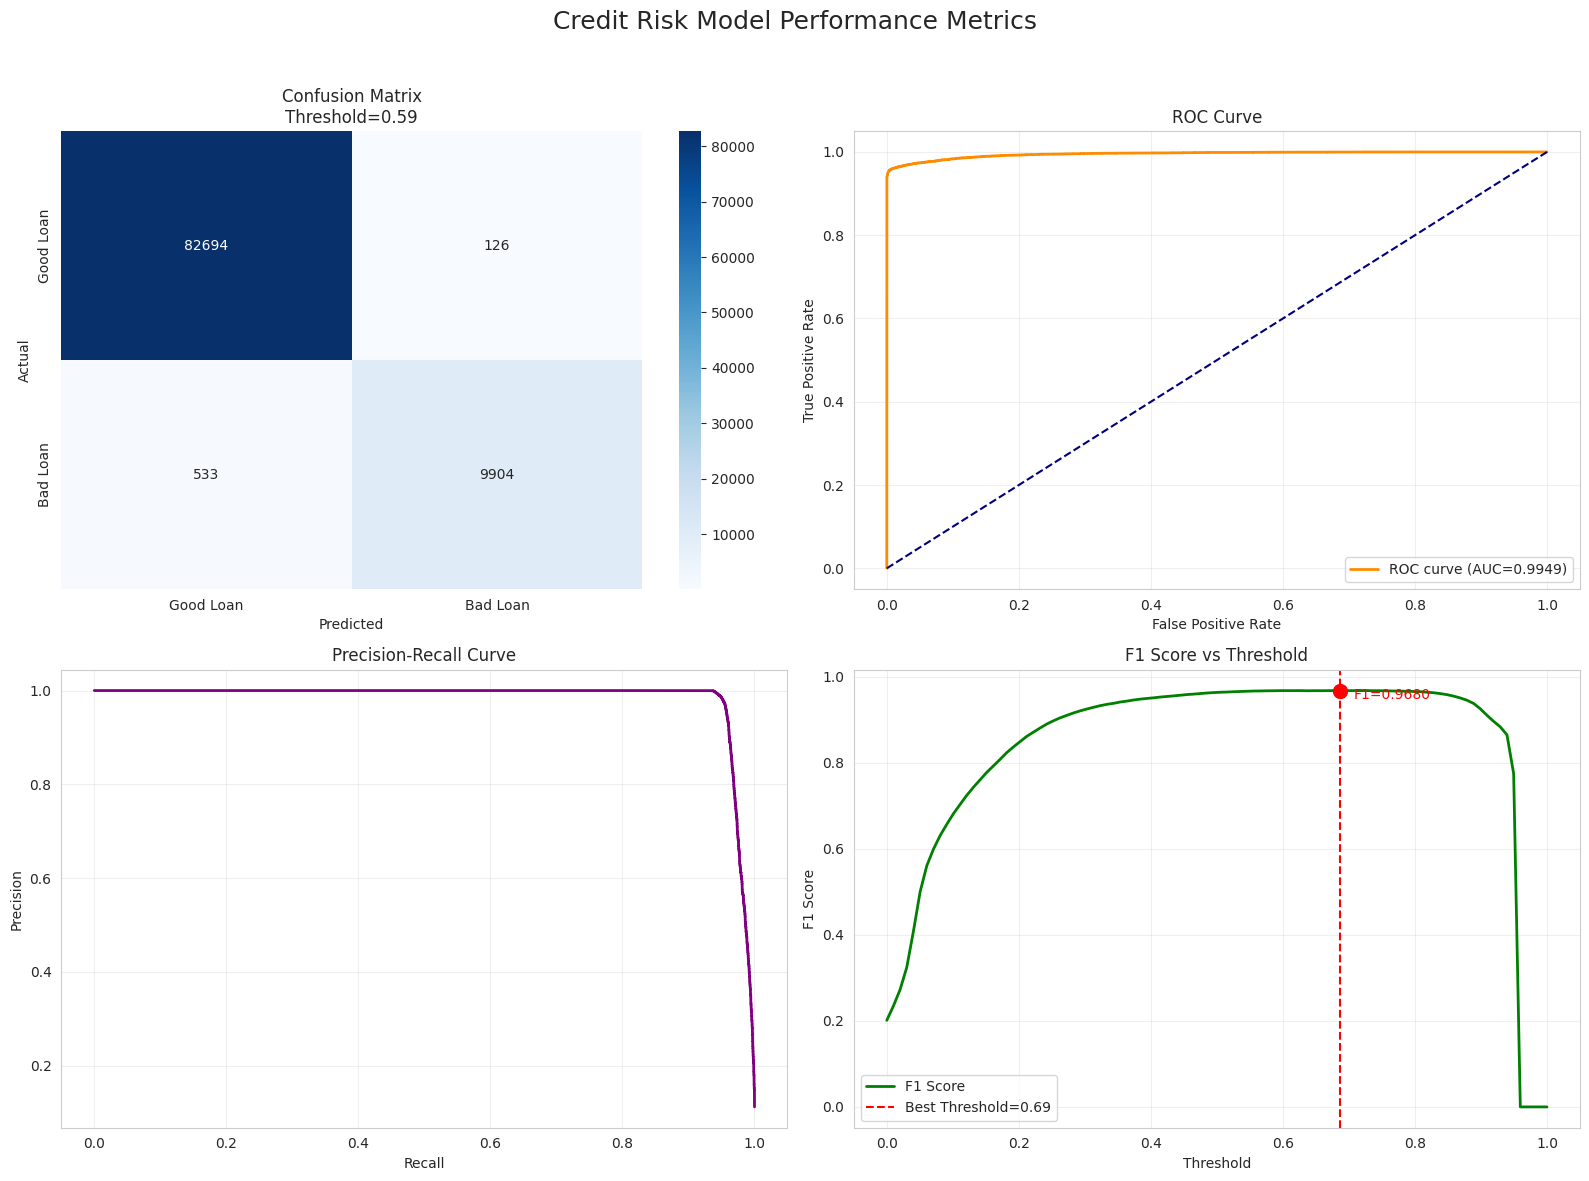


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

    Bad Loan     0.9874    0.9489    0.9678     10437
   Good Loan     0.9936    0.9985    0.9960     82820

    accuracy                         0.9929     93257
   macro avg     0.9905    0.9737    0.9819     93257
weighted avg     0.9929    0.9929    0.9929     93257



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve,
    precision_recall_curve, f1_score
)

# =========================
# 1. FINAL PREDICTIONS
# =========================
threshold = best_threshold
y_pred = (test_pred >= threshold).astype(int)
y_proba = test_pred

# Map ke business logic label
labels_map = {0: "Good Loan", 1: "Bad Loan"}
y_true_labels = y_test.map(labels_map)
y_pred_labels = pd.Series(y_pred, index=y_test.index).map(labels_map)

# =========================
# 2. CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true_labels, y_pred_labels, labels=["Good Loan","Bad Loan"])

# =========================
# 3. F1 vs Threshold
# =========================
thresholds = np.linspace(0,1,100)
f1_scores = [f1_score(y_test, (y_proba>=t).astype(int)) for t in thresholds]
best_f1_idx = np.argmax(f1_scores)
best_f1 = f1_scores[best_f1_idx]
best_f1_threshold = thresholds[best_f1_idx]

# =========================
# 4. PLOT ALL METRICS IN 1 FIGURE
# =========================
plt.figure(figsize=(16,12))

# --- Confusion Matrix ---
plt.subplot(2,2,1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Good Loan","Bad Loan"],
            yticklabels=["Good Loan","Bad Loan"])
plt.title(f'Confusion Matrix\nThreshold={threshold:.2f}')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# --- ROC Curve ---
plt.subplot(2,2,2)
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC={roc_auc:.4f})')
plt.plot([0,1], [0,1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

# --- Precision-Recall Curve ---
plt.subplot(2,2,3)
precision, recall, _ = precision_recall_curve(y_test, y_proba)
plt.plot(recall, precision, color='purple', lw=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(alpha=0.3)

# --- F1 vs Threshold ---
plt.subplot(2,2,4)
plt.plot(thresholds, f1_scores, color='green', lw=2, label='F1 Score')
plt.axvline(best_f1_threshold, color='red', linestyle='--', label=f'Best Threshold={best_f1_threshold:.2f}')
plt.scatter(best_f1_threshold, best_f1, color='red', s=100, zorder=5)
plt.text(best_f1_threshold+0.02, best_f1-0.02, f'F1={best_f1:.4f}', color='red')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.legend()
plt.grid(alpha=0.3)

plt.suptitle('Credit Risk Model Performance Metrics', fontsize=18)
plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

# =========================
# 5. CLASSIFICATION REPORT
# =========================
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_true_labels, y_pred_labels, digits=4))


# PREDICTION TEST-SET

In [ ]:
# =========================
# FINAL PREDICTION ON TEST SET (ALL FEATURES + BUSINESS LOGIC)
# =========================
threshold = best_threshold

# Probabilitas & predicted label
y_proba = test_pred
y_pred = (y_proba >= threshold).astype(int)

# Copy semua fitur numerik & kategori
pred_df = X_test.copy()

# Tambahkan kolom target sebenarnya (business logic)
pred_df["loan_status"] = y_test.map(
    lambda x: "Good Loan" if x == 0 else "Bad Loan"
)
pred_df["y_true"] = y_test.values
pred_df["y_proba"] = y_proba
pred_df["y_pred"] = y_pred

# =========================
# DISPLAY HEAD & TAIL
# =========================
print("\n===== PREDICTION SAMPLE (HEAD) =====")
display(pred_df.head(10))

print("\n===== PREDICTION SAMPLE (TAIL) =====")
display(pred_df.tail(10))


===== PREDICTION SAMPLE (HEAD) =====


,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,acc_now_delinq,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,loan_status,y_true,y_proba,y_pred
38664,7500,7500,873.25000,36 months,8.00,235.03,A,A3,2 years,MORTGAGE,10.778977,Verified,Jun-08,home_improvement,UT,4.28,0.0,Sep-86,0.0,31.0,76.0,3.0,0.0,3.970292,0.3,10.0,f,0.00,0.00,8460.75000,902.61,7500.00,960.75,0.0,0.0,0.0,Jul-11,235.07,Unknown,May-12,0.0,43.0,0.0,0.000000,81647.5,10.034560,Good Loan,0,0.042789,0
251508,12000,12000,12000.00000,36 months,9.49,384.34,B,B2,10+ years,MORTGAGE,11.002117,Not Verified,Nov-14,credit_card,CA,11.91,0.0,Oct-01,0.0,28.0,76.0,9.0,0.0,8.787831,73.6,19.0,f,8053.46,8053.46,4983.77000,4983.77,3946.54,1037.23,0.0,0.0,0.0,Dec-15,384.34,Jan-16,Jan-16,0.0,28.0,0.0,0.000000,312093.0,9.093919,Good Loan,0,0.120658,0
11299,30000,19600,19350.00000,60 months,17.49,492.29,D,D5,10+ years,RENT,11.338584,Verified,Jul-11,debt_consolidation,AZ,12.51,0.0,Oct-96,0.0,31.0,76.0,5.0,0.0,10.391761,65.7,27.0,f,0.00,0.00,29173.44263,28801.18,19600.00,9573.44,0.0,0.0,0.0,Oct-15,5095.94,Unknown,Oct-15,0.0,43.0,0.0,0.000000,81647.5,10.034560,Good Loan,0,0.010251,0
407595,10000,10000,10000.00000,36 months,12.99,336.90,B,B5,7 years,MORTGAGE,10.645449,Verified,Apr-14,debt_consolidation,NY,29.66,0.0,Sep-98,0.0,31.0,76.0,10.0,0.0,9.452973,88.5,15.0,w,4641.13,4641.13,7074.90000,7074.90,5358.87,1716.03,0.0,0.0,0.0,Jan-16,336.90,Feb-16,Jan-16,0.0,43.0,0.0,0.000000,32172.0,9.575053,Good Loan,0,0.041771,0
439516,14175,14175,14175.00000,60 months,22.45,395.14,E,E5,10+ years,MORTGAGE,10.491635,Verified,Feb-14,home_improvement,KS,2.30,0.0,Jul-88,1.0,31.0,76.0,7.0,0.0,7.207860,8.0,12.0,f,10685.71,10685.71,8693.08000,8693.08,3489.29,5203.79,0.0,0.0,0.0,Dec-15,395.14,Feb-16,Jan-16,0.0,43.0,0.0,6.426488,1349.0,9.729194,Good Loan,0,0.128221,0
51942,10925,10925,10925.00000,60 months,19.97,289.27,D,D5,9 years,MORTGAGE,10.819798,Source Verified,Dec-13,credit_card,AZ,32.31,0.0,Dec-97,2.0,31.0,119.0,11.0,1.0,10.151051,80.1,30.0,f,0.00,0.00,12658.43792,12658.44,10925.00,1733.44,0.0,0.0,0.0,Oct-14,10055.83,Unknown,Jan-16,0.0,43.0,0.0,0.000000,191615.0,10.373522,Good Loan,0,0.009540,0
216002,15000,15000,15000.00000,60 months,10.74,324.20,B,B2,5 years,MORTGAGE,10.819798,Not Verified,Jun-12,major_purchase,FL,15.13,0.0,Nov-99,0.0,31.0,76.0,9.0,0.0,8.853094,22.1,25.0,f,0.00,0.00,17808.58168,17808.58,15000.00,2808.58,0.0,0.0,0.0,Jul-14,10030.18,Unknown,Jul-14,0.0,43.0,0.0,0.000000,81647.5,10.034560,Good Loan,0,0.008876,0
285584,13950,13950,13950.00000,36 months,13.98,476.65,C,C3,10+ years,MORTGAGE,11.387158,Not Verified,Oct-14,debt_consolidation,SC,20.16,0.0,Jun-02,1.0,31.0,108.0,13.0,1.0,9.250522,31.6,32.0,w,0.00,0.00,14461.13000,14461.13,13950.00,511.13,0.0,0.0,0.0,Jan-15,13518.66,Unknown,Jan-15,0.0,43.0,0.0,0.000000,102256.0,10.401258,Good Loan,0,0.008919,0
463521,20000,20000,19975.00000,36 months,6.03,608.72,A,A1,10+ years,MORTGAGE,11.775297,Source Verified,Jan-14,credit_card,TX,12.54,0.0,Mar-00,0.0,31.0,76.0,14.0,0.0,9.886138,46.0,42.0,f,0.00,0.00,14608.99000,14590.73,12928.56,1680.43,0.0,0.0,0.0,Jan-16,7690.58,Unknown,Jan-16,0.0,43.0,0.0,0.000000,264460.0,10.661978,Good Loan,0,0.015049,0
22471,12000,12000,11341.50142,36 months,6.91,370.04,A,A5,< 1 year,RENT,11.041337,Source Verified,Dec-10,debt_consolidation,WA,17.92,0.0,Feb-93,0.0,27.0,114.0,16.0,1.0,9.009814,42.8,31.0,f,0.00,0.00,13320.76000,12525.19,12000.00,1320.76,0.0,0.0,0.0,Dec-13,374.30,Unknown,Jan-16,0.0,43.0,0.0,0.000000,


===== PREDICTION SAMPLE (TAIL) =====


,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,acc_now_delinq,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,loan_status,y_true,y_proba,y_pred
249309,10000,10000,10000.000000,36 months,9.49,320.29,B,B2,3 years,RENT,11.451061,Source Verified,Nov-14,debt_consolidation,CT,20.43,0.0,Jul-93,1.0,29.0,76.0,7.0,0.0,8.193677,86.1,23.0,f,6443.91,6443.91,4473.52000,4473.52,3556.09,917.43,0.000000,0.0,0.0,Jan-16,320.29,Feb-16,Jan-16,0.0,29.0,0.0,5.645447,77318.0,8.343078,Good Loan,0,0.033870,0
347989,18500,18500,18500.000000,60 months,9.17,385.56,B,B1,2 years,MORTGAGE,11.925042,Verified,Jul-14,debt_consolidation,NC,22.16,0.0,Nov-88,0.0,31.0,76.0,18.0,0.0,10.378043,56.4,60.0,w,13807.12,13807.12,6940.08000,6940.08,4692.88,2247.20,0.000000,0.0,0.0,Jan-16,385.56,Feb-16,Jan-16,0.0,43.0,0.0,0.000000,186857.0,10.950824,Good Loan,0,0.026978,0
50874,11200,11200,11200.000000,36 months,10.99,366.63,B,B2,6 years,MORTGAGE,11.561725,Source Verified,Dec-13,debt_consolidation,CA,10.42,0.0,Sep-03,2.0,31.0,76.0,8.0,0.0,8.902456,35.5,24.0,f,3821.74,3821.74,9162.63000,9162.63,7378.26,1784.37,0.000000,0.0,0.0,Jan-16,366.63,Feb-16,Jan-16,0.0,43.0,0.0,0.000000,384172.0,9.937937,Good Loan,0,0.035194,0
140445,18000,18000,17925.000000,60 months,21.00,486.97,E,E2,10+ years,RENT,10.645449,Verified,May-13,debt_consolidation,PA,20.86,0.0,May-02,0.0,31.0,76.0,15.0,0.0,9.814492,91.0,21.0,f,10710.43,10665.79,15572.33000,15507.48,7289.57,8282.76,0.000000,0.0,0.0,Jan-16,486.97,Feb-16,Jan-16,0.0,43.0,0.0,0.000000,18296.0,9.908525,Good Loan,0,0.049115,0
28076,10000,10000,10000.000000,36 months,10.75,326.21,B,B2,2 years,MORTGAGE,10.596560,Verified,Jul-10,debt_consolidation,AZ,1.65,0.0,Jun-94,1.0,31.0,76.0,3.0,0.0,7.457609,19.2,21.0,f,0.00,0.00,11740.35000,11740.35,9999.99,1740.36,0.000000,0.0,0.0,Jul-13,347.12,Unknown,Jul-13,0.0,43.0,0.0,0.000000,81647.5,10.034560,Good Loan,0,0.030154,0
384945,10000,10000,10000.000000,60 months,19.52,262.28,E,E2,10+ years,MORTGAGE,10.373522,Verified,May-14,debt_consolidation,IL,16.17,0.0,Nov-90,2.0,31.0,48.0,8.0,1.0,8.438150,37.0,33.0,w,7802.98,7802.98,4983.32000,4983.32,2197.02,2786.30,0.000000,0.0,0.0,Jan-16,262.28,Feb-16,Jan-16,0.0,72.0,0.0,0.000000,144899.0,9.441531,Good Loan,0,0.045112,0
464682,12000,12000,12000.000000,60 months,16.24,293.35,C,C5,Unknown,MORTGAGE,10.803486,Verified,Jan-14,credit_card,MD,13.68,0.0,Apr-96,1.0,31.0,76.0,18.0,0.0,10.164466,46.3,52.0,f,0.00,0.00,13541.29413,13541.29,12000.00,1541.30,0.000000,0.0,0.0,Nov-14,10901.15,Unknown,Nov-14,0.0,31.0,0.0,0.000000,233925.0,10.934909,Good Loan,0,0.008613,0
261146,11200,11200,11200.000000,60 months,19.99,296.67,E,E3,5 years,MORTGAGE,11.407576,Verified,Nov-14,debt_consolidation,FL,10.15,0.0,Nov-06,2.0,31.0,76.0,17.0,0.0,9.576857,44.0,28.0,f,0.00,0.00,1767.58000,1767.58,688.71,1078.87,0.000000,0.0,0.0,Jun-15,296.67,Unknown,Dec-15,0.0,43.0,0.0,6.484635,268977.0,10.398214,Bad Loan,1,0.952482,1
40763,10000,10000,9853.154844,36 months,12.87,336.34,C,C1,4 years,MORTGAGE,11.563485,Not Verified,Jan-10,moving,CA,5.59,0.0,Dec-89,6.0,62.0,76.0,5.0,0.0,8.422443,68.9,26.0,f,0.00,0.00,12242.93000,12070.31,10000.00,2227.95,14.984193,0.0,0.0,Mar-13,197.57,Mar-13,Feb-13,0.0,43.0,0.0,0.000000,81647.5,10.034560,Good Loan,0,0.021427,0
89759,16000,16000,15925.000000,36 months,9.99,516.20,B,B1,6 years,MORTGAGE,11.407576,Verified,Sep-13,debt_consolidation,MI,16.69,0.0,May-96,0.0,36.0,76.0,18.0,0.0,9.544381,47.8,47.0,f,0.00,0.00,17284.08697,17203.07,16000.00,1284.09,0.000000,0.0,0.

## SAVE PREDICTION RESULT

In [ ]:
# =========================
# SAVE TO CSV
# =========================
os.makedirs("predictions", exist_ok=True)
pred_df.to_csv("predictions/test_set_predictions_full.csv", index=False)
print("\n===== Predictions saved to 'predictions/test_set_predictions_full.csv' =====")



===== Predictions saved to 'predictions/test_set_predictions_full.csv' =====
